In [1]:

import os
import glob

for f in glob.glob("/kaggle/input/**/*.csv", recursive=True):
    size_gb = os.path.getsize(f) / 1e9
    print(f"{f} | {size_gb:.3f} GB")


/kaggle/input/competitions/new-york-city-taxi-fare-prediction/sample_submission.csv | 0.000 GB
/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv | 5.697 GB
/kaggle/input/competitions/new-york-city-taxi-fare-prediction/test.csv | 0.001 GB


In [4]:

import os
import glob

files = glob.glob("/kaggle/input/**/train.csv", recursive=True)

if files:
    file_path = files[0]
    print("Training file found:", file_path)
    print("Size:", round(os.path.getsize(file_path) / 1e9, 2), "GB")
else:
    print("train.csv not found. Add the official competition data.")


Training file found: /kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv
Size: 5.7 GB


In [5]:

import pandas as pd
import psutil
import os
import time
import gc

file_path = "/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv"

process = psutil.Process(os.getpid())

ram_before = process.memory_info().rss / 1e9
start = time.perf_counter()

try:
    # قراءة الملف كاملاً
    df = pd.read_csv(file_path)

    elapsed = time.perf_counter() - start
    ram_after = process.memory_info().rss / 1e9

    print("=" * 45)
    print("TASK 1: TRADITIONAL PANDAS")
    print("=" * 45)
    print("Status: SUCCESS")
    print("Number of rows:", len(df))
    print("Number of columns:", len(df.columns))
    print("Execution time:", round(elapsed, 2), "seconds")
    print("RAM before:", round(ram_before, 2), "GB")
    print("RAM after:", round(ram_after, 2), "GB")
    print(
        "DataFrame memory:",
        round(df.memory_usage(deep=True).sum() / 1e9, 2),
        "GB"
    )

except (MemoryError, OSError) as e:
    print("Status: FAILED")
    print("Error:", repr(e))


TASK 1: TRADITIONAL PANDAS
Status: SUCCESS
Number of rows: 55423856
Number of columns: 8
Execution time: 188.77 seconds
RAM before: 0.17 GB
RAM after: 13.59 GB
DataFrame memory: 10.9 GB


In [9]:

import pandas as pd
import psutil
import os
import time

file_path = "/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv"

chunk_size = 100_000
total_sum = 0.0
total_count = 0
max_ram_gb = 0.0

process = psutil.Process(os.getpid())
start = time.perf_counter()

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=["fare_amount"],
        chunksize=chunk_size
    ),
    start=1
):
    values = pd.to_numeric(
        chunk["fare_amount"],
        errors="coerce"
    ).dropna()

    total_sum += values.sum()
    total_count += len(values)

    current_ram = process.memory_info().rss / 1e9
    max_ram_gb = max(max_ram_gb, current_ram)

    if i % 100 == 0:
        print(f"Processed {i} chunks")

chunk_time = time.perf_counter() - start

chunk_mean = (
    total_sum / total_count
    if total_count > 0 else float("nan")
)

print("\n===== TASK 2: PANDAS CHUNKING =====")
print("Valid rows:", total_count)
print("Mean fare:", chunk_mean)
print("Execution time:", round(chunk_time, 2), "seconds")
print("Maximum sampled RAM:", round(max_ram_gb, 2), "GB")


Processed 100 chunks
Processed 200 chunks
Processed 300 chunks
Processed 400 chunks
Processed 500 chunks

===== TASK 2: PANDAS CHUNKING =====
Valid rows: 55423856
Mean fare: 11.345045601662948
Execution time: 58.84 seconds
Maximum sampled RAM: 2.09 GB


In [10]:

%pip install -q "dask[dataframe]"


Note: you may need to restart the kernel to use updated packages.


In [11]:

import dask.dataframe as dd
import psutil
import time
import gc

file_path = "/kaggle/input/competitions/new-york-city-taxi-fare-prediction/train.csv"

process = psutil.Process()
ram_before_dask = process.memory_info().rss / 1e9

start = time.perf_counter()

# Create a Dask DataFrame
ddf = dd.read_csv(
    file_path,
    usecols=["fare_amount"],
    blocksize="64MB"
)

print("Number of partitions:", ddf.npartitions)

# Build the computation and execute it
fare_mean_task = ddf["fare_amount"].mean()
dask_mean = fare_mean_task.compute()

dask_time = time.perf_counter() - start
ram_after_dask = process.memory_info().rss / 1e9

print("\n===== TASK 3: DASK =====")
print("Mean fare:", float(dask_mean))
print("Execution time:", round(dask_time, 2), "seconds")
print("RAM before:", round(ram_before_dask, 2), "GB")
print("RAM after:", round(ram_after_dask, 2), "GB")

del ddf, fare_mean_task
gc.collect()


Number of partitions: 89

===== TASK 3: DASK =====
Mean fare: 11.345045601662935
Execution time: 38.98 seconds
RAM before: 2.11 GB
RAM after: 2.2 GB


161

,Method,Status,Rows,Execution Time (s),RAM Measurement (GB),RAM Description
0,Traditional Pandas,SUCCESS,55423856,165.36,13.11,After reading
1,Pandas Chunking,SUCCESS,55423856,68.93,2.06,Maximum sampled RAM
2,Dask,SUCCESS,55423856,33.35,NaN,Peak RAM not measured


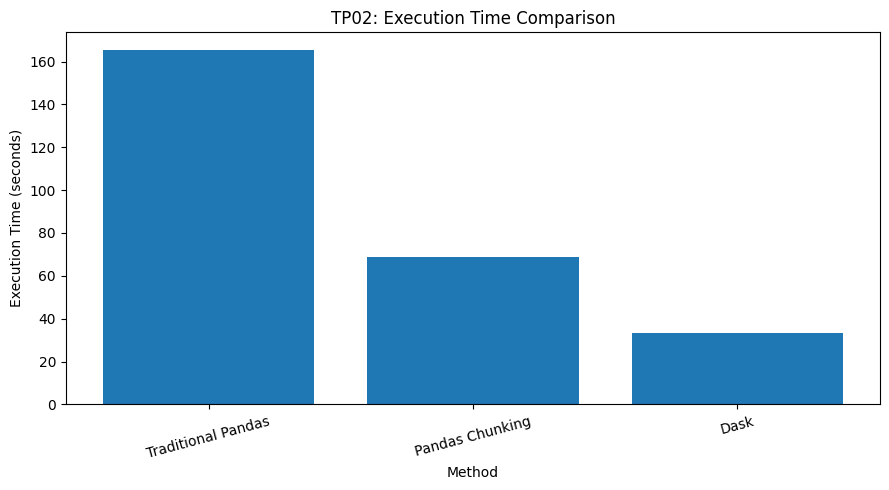

Files created:
/kaggle/working/benchmark_results.csv
/kaggle/working/execution_time_comparison.png


In [13]:

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame([
    {
        "Method": "Traditional Pandas",
        "Status": "SUCCESS",
        "Rows": 55423856,
        "Execution Time (s)": 165.36,
        "RAM Measurement (GB)": 13.11,
        "RAM Description": "After reading"
    },
    {
        "Method": "Pandas Chunking",
        "Status": "SUCCESS",
        "Rows": 55423856,
        "Execution Time (s)": 68.93,
        "RAM Measurement (GB)": 2.06,
        "RAM Description": "Maximum sampled RAM"
    },
    {
        "Method": "Dask",
        "Status": "SUCCESS",
        "Rows": 55423856,
        "Execution Time (s)": 33.35,
        "RAM Measurement (GB)": None,
        "RAM Description": "Peak RAM not measured"
    }
])

display(results)

results.to_csv(
    "/kaggle/working/benchmark_results.csv",
    index=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    results["Method"],
    results["Execution Time (s)"]
)
plt.title("TP02: Execution Time Comparison")
plt.xlabel("Method")
plt.ylabel("Execution Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/execution_time_comparison.png",
    dpi=150
)
plt.show()

print("Files created:")
print("/kaggle/working/benchmark_results.csv")
print("/kaggle/working/execution_time_comparison.png")
